###### import sys

print(sys.executable)
print(sys.version)

In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv('data.csv')
len(df)

11914

In [3]:
df.shape

(11914, 16)

In [4]:
df.columns.tolist()

['Make',
 'Model',
 'Year',
 'Engine Fuel Type',
 'Engine HP',
 'Engine Cylinders',
 'Transmission Type',
 'Driven_Wheels',
 'Number of Doors',
 'Market Category',
 'Vehicle Size',
 'Vehicle Style',
 'highway MPG',
 'city mpg',
 'Popularity',
 'MSRP']

In [5]:
df.dtypes

Make                  object
Model                 object
Year                   int64
Engine Fuel Type      object
Engine HP            float64
Engine Cylinders     float64
Transmission Type     object
Driven_Wheels         object
Number of Doors      float64
Market Category       object
Vehicle Size          object
Vehicle Style         object
highway MPG            int64
city mpg               int64
Popularity             int64
MSRP                   int64
dtype: object

In [6]:
df.isna().sum()

Make                    0
Model                   0
Year                    0
Engine Fuel Type        3
Engine HP              69
Engine Cylinders       30
Transmission Type       0
Driven_Wheels           0
Number of Doors         6
Market Category      3742
Vehicle Size            0
Vehicle Style           0
highway MPG             0
city mpg                0
Popularity              0
MSRP                    0
dtype: int64

In [7]:
missing = df.isna().sum().sort_values(ascending=False)

missing[missing > 0]

Market Category     3742
Engine HP             69
Engine Cylinders      30
Number of Doors        6
Engine Fuel Type       3
dtype: int64

In [8]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

string_columns = list(df.dtypes[df.dtypes == 'object'].index)

for col in string_columns:
    df[col] = df[col].str.lower().str.replace(' ', '_')

In [9]:
df.head(n=200)

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,mitsubishi,3000gt,1997,regular_unleaded,161.0,6.0,manual,front_wheel_drive,2.0,hatchback,compact,2dr_hatchback,22,17,436,3295
196,mitsubishi,3000gt,1997,regular_unleaded,320.0,6.0,manual,all_wheel_drive,2.0,"hatchback,factory_tuner,performance",compact,2dr_hatchback,22,16,436,6008
197,mitsubishi,3000gt,1998,regular_unleaded,320.0,6.0,manual,all_wheel_drive,2.0,"hatchback,factory_tuner,performance",compact,2dr_hatchback,22,16,436,6710
198,mitsubishi,3000gt,1998,regular_unleaded,161.0,6.0,manual,front_wheel_drive,2.0,hatchback,compact,2dr_hatchback,22,17,436,3701


In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,11914.0,2010.384338,7.579740,1990.0,2007.0,2015.0,2016.00,2017.0
engine_hp,11845.0,249.386070,109.191870,55.0,170.0,227.0,300.00,1001.0
engine_cylinders,11884.0,5.628829,1.780559,0.0,4.0,6.0,6.00,16.0
number_of_doors,11908.0,3.436093,0.881315,2.0,2.0,4.0,4.00,4.0
highway_mpg,11914.0,26.637485,8.863001,12.0,22.0,26.0,30.00,354.0
city_mpg,11914.0,19.733255,8.987798,7.0,16.0,18.0,22.00,137.0
popularity,11914.0,1554.911197,1441.855347,2.0,549.0,1385.0,2009.00,5657.0
msrp,11914.0,40594.737032,60109.103604,2000.0,21000.0,29995.0,42231.25,2065902.0


## Exploratory data analysis

In [11]:
df.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='object')

In [12]:
df.msrp.describe()

count    1.191400e+04
mean     4.059474e+04
std      6.010910e+04
min      2.000000e+03
25%      2.100000e+04
50%      2.999500e+04
75%      4.223125e+04
max      2.065902e+06
Name: msrp, dtype: float64

<Axes: >

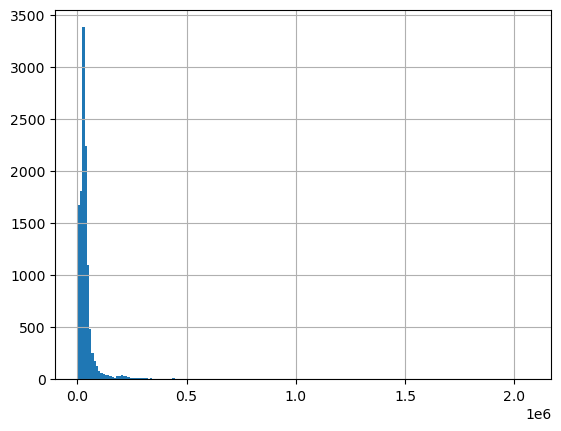

In [13]:
df.msrp.hist(bins=50)

In [14]:
np.percentile(df.msrp, [0, 25, 50, 75, 90, 95, 99, 100])

array([2.0000000e+03, 2.1000000e+04, 2.9995000e+04, 4.2231250e+04,
       6.5080000e+04, 1.0753025e+05, 2.8448812e+05, 2.0659020e+06])

In [15]:
df.msrp.max()

2065902

<Axes: xlabel='year', ylabel='msrp'>

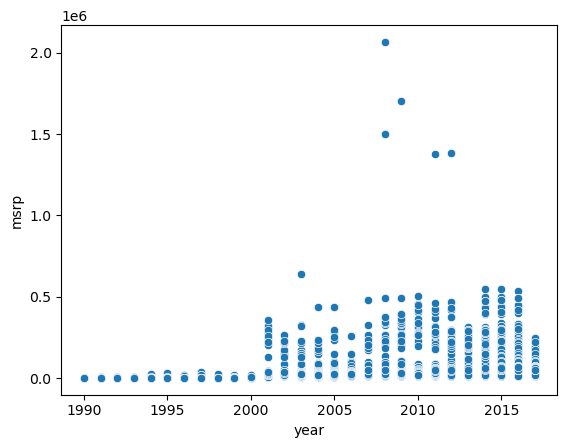

In [16]:
sns.scatterplot(
    data=df,
    x='year',
    y='msrp'
)

<Axes: xlabel='engine_hp', ylabel='msrp'>

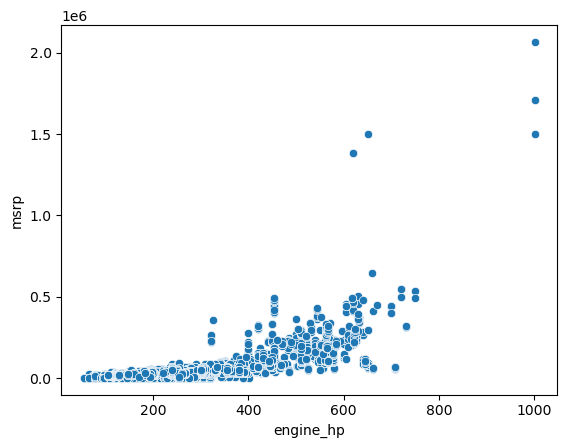

In [17]:
sns.scatterplot(
    data=df,
    x='engine_hp',
    y='msrp'
)

<Axes: xlabel='make', ylabel='msrp'>

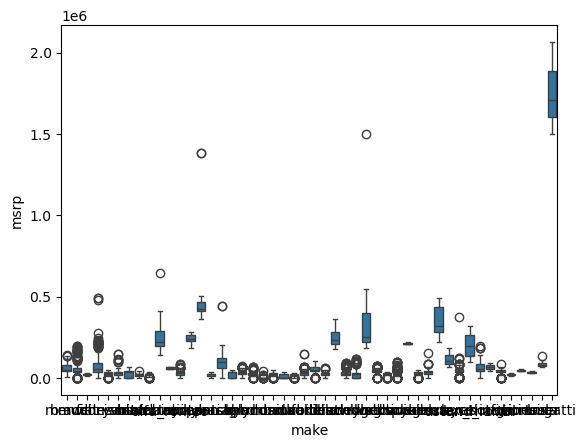

In [18]:
sns.boxplot(
    data=df,
    x='make',
    y='msrp'
)

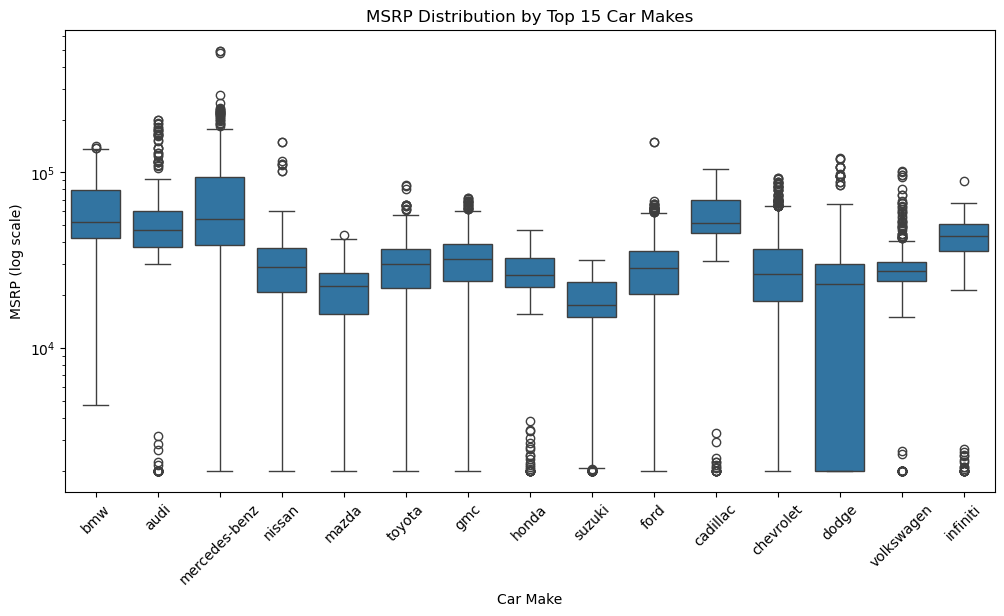

In [19]:
top_makes = df['make'].value_counts().head(15).index
df_top = df[df['make'].isin(top_makes)]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_top,
    x='make',
    y='msrp'
)

plt.yscale('log')

plt.xticks(rotation=45)
plt.title('MSRP Distribution by Top 15 Car Makes')
plt.xlabel('Car Make')
plt.ylabel('MSRP (log scale)')

plt.show()

In [20]:
median_msrp = (
    df.groupby('make')['msrp']
      .median()
      .sort_values(ascending=False)
      .head(15)
)

median_msrp

make
bugatti         1705769.0
maybach          426975.0
rolls-royce      319400.0
lamborghini      251600.0
mclaren          239400.0
bentley          231600.0
ferrari          224585.0
spyker           209990.0
aston_martin     195895.0
maserati         107400.0
porsche           98300.0
tesla             79700.0
lotus             68300.0
alfa_romeo        63900.0
land_rover        55300.0
Name: msrp, dtype: float64

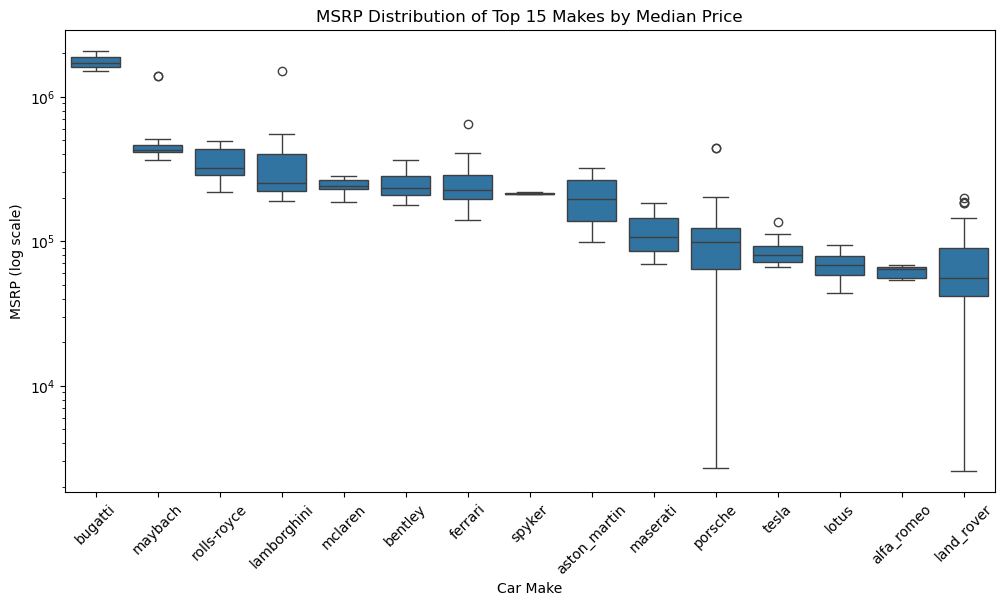

In [21]:
top_expensive_makes = median_msrp.index

df_expensive = df[df['make'].isin(top_expensive_makes)]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_expensive,
    x='make',
    y='msrp',
    order=median_msrp.index
)

plt.xticks(rotation=45)
plt.yscale('log')

plt.title('MSRP Distribution of Top 15 Makes by Median Price')
plt.xlabel('Car Make')
plt.ylabel('MSRP (log scale)')

plt.show()

<Axes: xlabel='vehicle_style', ylabel='msrp'>

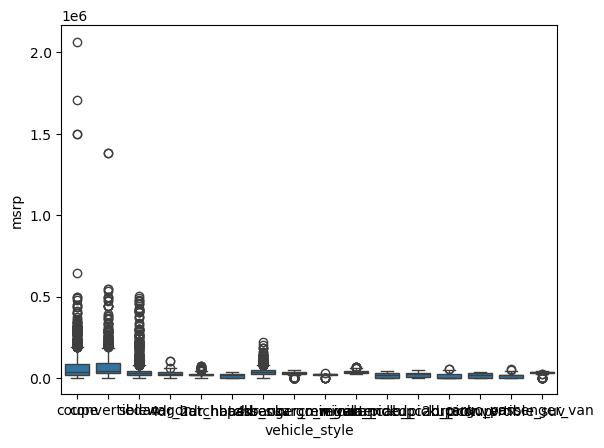

In [22]:
sns.boxplot(
    data=df,
    x='vehicle_style',
    y='msrp'
)

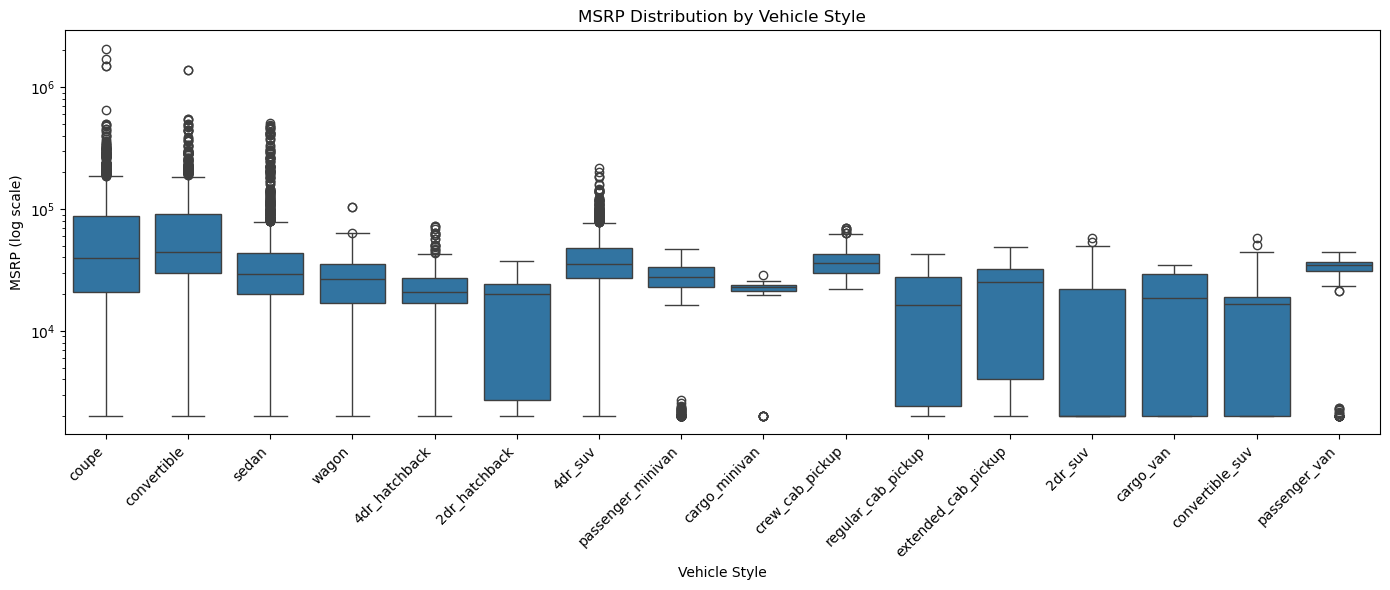

In [23]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x='vehicle_style',
    y='msrp'
)

plt.yscale('log')
plt.xticks(rotation=45, ha='right')

plt.xlabel('Vehicle Style')
plt.ylabel('MSRP (log scale)')
plt.title('MSRP Distribution by Vehicle Style')

plt.tight_layout()
plt.show()

In [24]:
df['vehicle_style'].value_counts()

vehicle_style
sedan                  3048
4dr_suv                2488
coupe                  1211
convertible             793
4dr_hatchback           702
crew_cab_pickup         681
extended_cab_pickup     623
wagon                   592
2dr_hatchback           506
passenger_minivan       417
regular_cab_pickup      392
2dr_suv                 138
passenger_van           128
cargo_van                95
cargo_minivan            71
convertible_suv          29
Name: count, dtype: int64

In [25]:
top_styles = df['vehicle_style'].value_counts().head(10).index

df_top = df[df['vehicle_style'].isin(top_styles)]

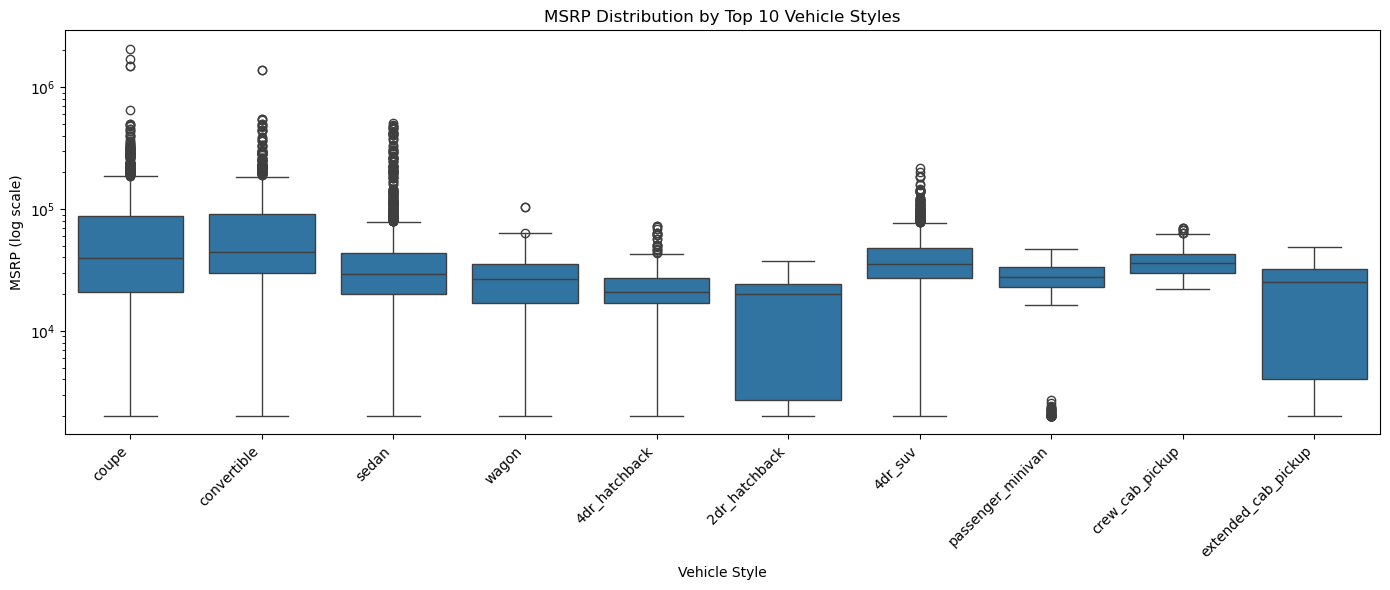

In [26]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df_top,
    x='vehicle_style',
    y='msrp'
)

plt.yscale('log')
plt.xticks(rotation=45, ha='right')

plt.xlabel('Vehicle Style')
plt.ylabel('MSRP (log scale)')
plt.title('MSRP Distribution by Top 10 Vehicle Styles')

plt.tight_layout()
plt.show()

In [27]:
median_msrp = (
    df.groupby('vehicle_style')['msrp']
      .median()
      .sort_values(ascending=False)
)

median_msrp

vehicle_style
convertible            44350.0
coupe                  39250.0
crew_cab_pickup        35980.0
4dr_suv                35557.5
passenger_van          34525.0
sedan                  29472.5
passenger_minivan      27700.0
wagon                  26472.5
extended_cab_pickup    25395.0
cargo_minivan          22695.0
4dr_hatchback          20992.5
2dr_hatchback          20157.5
cargo_van              18740.0
convertible_suv        16599.0
regular_cab_pickup     16220.0
2dr_suv                 2000.0
Name: msrp, dtype: float64

In [28]:
top_expensive_styles = median_msrp.head(10).index

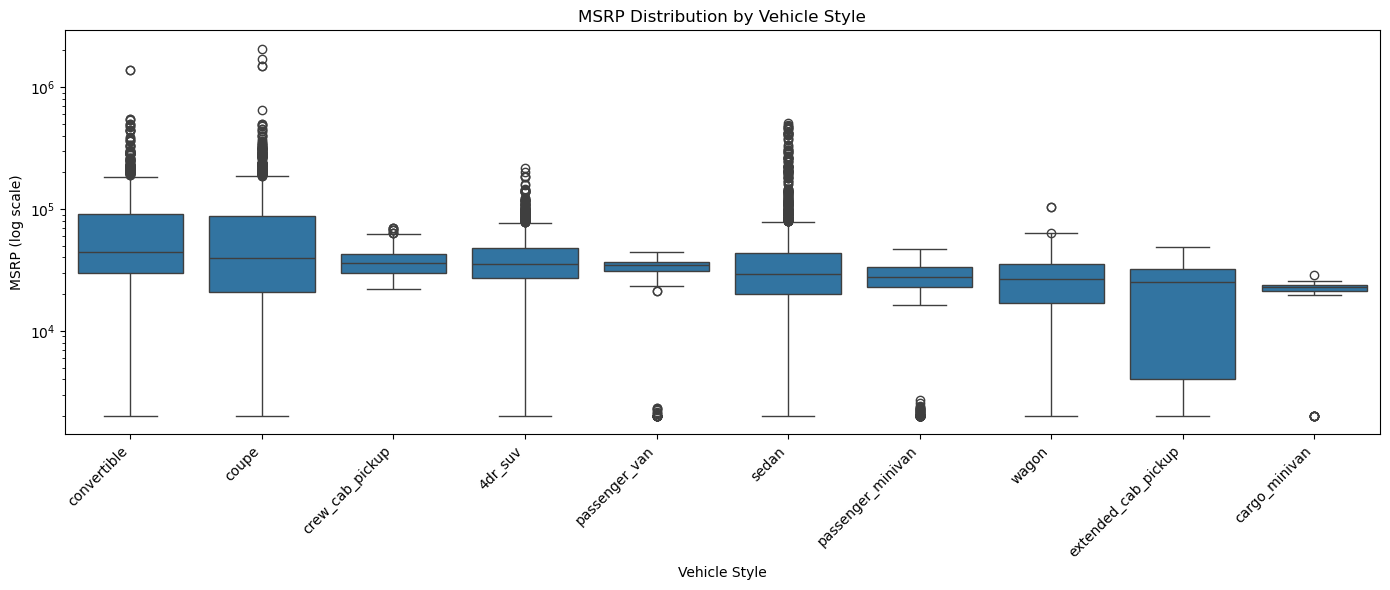

In [29]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df[df['vehicle_style'].isin(top_expensive_styles)],
    x='vehicle_style',
    y='msrp',
    order=top_expensive_styles
)

plt.yscale('log')
plt.xticks(rotation=45, ha='right')

plt.xlabel('Vehicle Style')
plt.ylabel('MSRP (log scale)')
plt.title('MSRP Distribution by Vehicle Style')
plt.tight_layout()

plt.show()

In [30]:
log_price = np.log1p(df.msrp)

<Axes: xlabel='vehicle_style', ylabel='msrp'>

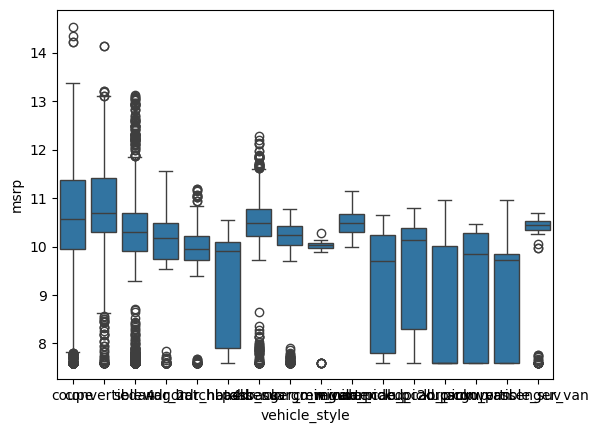

In [31]:
sns.boxplot(
    data=df,
    x='vehicle_style',
    y=log_price
)

In [32]:
df.select_dtypes(include='number').corr()

,year,engine_hp,engine_cylinders,number_of_doors,highway_mpg,city_mpg,popularity,msrp
year,1.000000,0.351794,-0.041479,0.263787,0.258240,0.198171,0.073049,0.227590
engine_hp,0.351794,1.000000,0.779988,-0.102713,-0.406563,-0.439371,0.037501,0.662008
engine_cylinders,-0.041479,0.779988,1.000000,-0.140088,-0.621606,-0.600776,0.041145,0.531312
number_of_doors,0.263787,-0.102713,-0.140088,1.000000,0.118570,0.120881,-0.048272,-0.126635
highway_mpg,0.258240,-0.406563,-0.621606,0.118570,1.000000,0.886829,-0.020991,-0.160043
city_mpg,0.198171,-0.439371,-0.600776,0.120881,0.886829,1.000000,-0.003217,-0.157676
popularity,0.073049,0.037501,0.041145,-0.048272,-0.020991,-0.003217,1.000000,-0.048476
msrp,0.227590,0.662008,0.531312,-0.126635,-0.160043,-0.157676,-0.048476,1.000000


<Axes: >

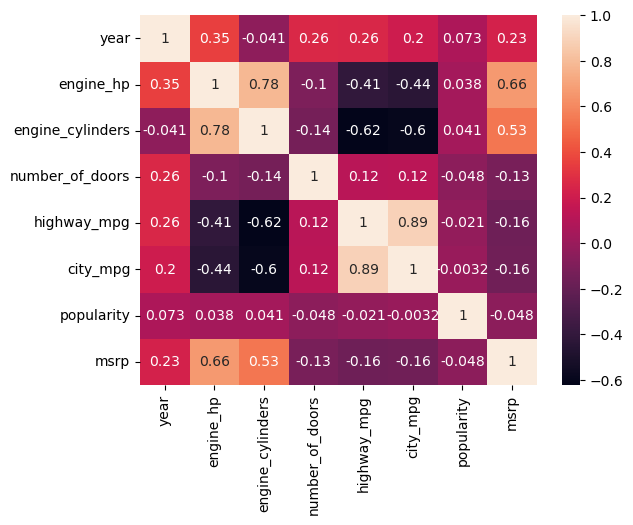

In [33]:
sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True
)

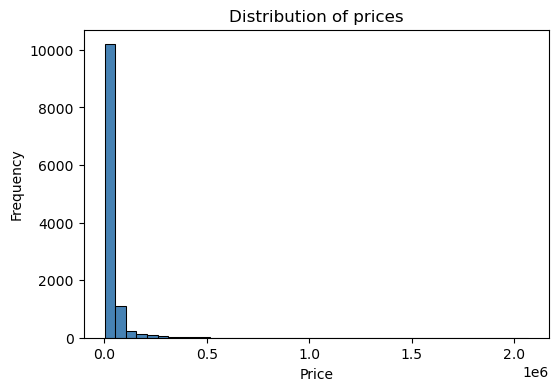

In [34]:
plt.figure(figsize=(6, 4))

sns.histplot(df.msrp, bins=40, color='steelblue', alpha=1)
plt.ylabel('Frequency')
plt.xlabel('Price')
plt.title('Distribution of prices')

plt.show()

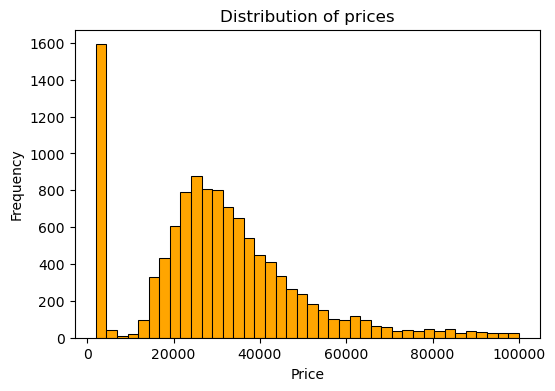

In [35]:
plt.figure(figsize=(6, 4))

sns.histplot(df.msrp[df.msrp < 100000], bins=40, color='orange', alpha=1)
plt.ylabel('Frequency')
plt.xlabel('Price')
plt.title('Distribution of prices')

plt.show()

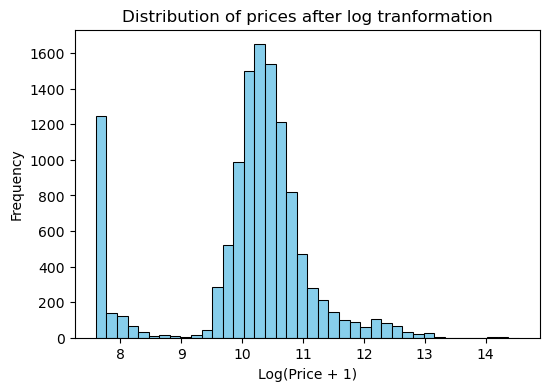

In [36]:
log_price = np.log1p(df.msrp)

plt.figure(figsize=(6, 4))

sns.histplot(log_price, bins=40, color='skyblue', alpha=1)
plt.ylabel('Frequency')
plt.xlabel('Log(Price + 1)')
plt.title('Distribution of prices after log tranformation')

plt.show()

In [37]:
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

## Validation framework

In [38]:
np.random.seed(2)

n = len(df)

n_val = int(0.2 * n)
n_test = int(0.2 * n)
n_train = n - (n_val + n_test)

idx = np.arange(n)
np.random.shuffle(idx)

df_shuffled = df.iloc[idx]

df_train = df_shuffled.iloc[:n_train].copy()
df_val = df_shuffled.iloc[n_train:n_train+n_val].copy()
df_test = df_shuffled.iloc[n_train+n_val:].copy()

In [39]:
y_train_orig = df_train.msrp.values
y_val_orig = df_val.msrp.values
y_test_orig = df_test.msrp.values

y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

## Linear Regression

In [40]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

## Baseline solution

In [41]:
base = ['engine_hp', 'engine_cylinders', 'highway_mpg', 'city_mpg', 'popularity']

In [42]:
def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [43]:
X_train = prepare_X(df_train)
w_0, w = train_linear_regression(X_train, y_train)

In [44]:
y_pred = w_0 + X_train.dot(w)

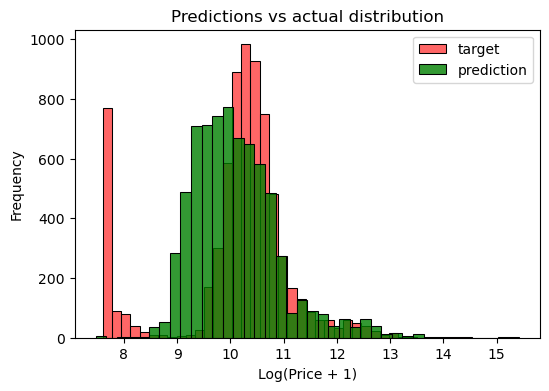

In [45]:
plt.figure(figsize=(6, 4))

sns.histplot(y_train, label='target', color='red', alpha=0.6, bins=40)
sns.histplot(y_pred, label='prediction', color='green', alpha=0.8, bins=40)

plt.legend()

plt.ylabel('Frequency')
plt.xlabel('Log(Price + 1)')
plt.title('Predictions vs actual distribution')

plt.show()

In [46]:
def rmse(y, y_pred):
    error = y_pred - y
    mse = (error ** 2).mean()
    return np.sqrt(mse)

In [47]:
rmse(y_train, y_pred)

np.float64(0.7554192603920132)

In [48]:
X_val = prepare_X(df_val)
y_pred = w_0 + X_val.dot(w)

In [49]:
rmse(y_val, y_pred)

np.float64(0.7616530991301561)

## Simple feature engineering

In [50]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [51]:
X_train = prepare_X(df_train)
w_0, w = train_linear_regression(X_train, y_train)

y_pred = w_0 + X_train.dot(w)
print('train', rmse(y_train, y_pred))

X_val = prepare_X(df_val)
y_pred = w_0 + X_val.dot(w)
print('validation', rmse(y_val, y_pred))

train 0.5175055465840046
validation 0.5172055461058324


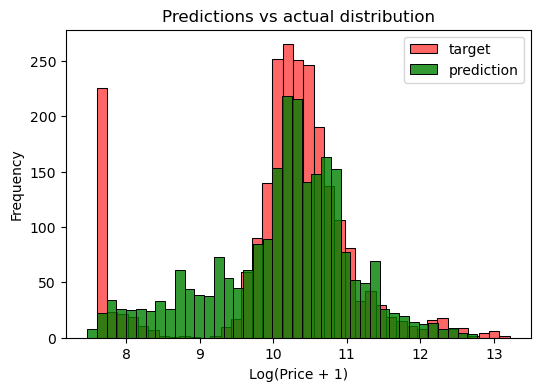

In [52]:
plt.figure(figsize=(6, 4))


sns.histplot(y_val, label='target', color='red', alpha=0.6, bins=40)
sns.histplot(y_pred, label='prediction', color='green', alpha=0.8, bins=40)

plt.legend()

plt.ylabel('Frequency')
plt.xlabel('Log(Price + 1)')
plt.title('Predictions vs actual distribution')

plt.show()

In [53]:
df['make'].value_counts().head(5)

make
chevrolet     1123
ford           881
volkswagen     809
toyota         746
dodge          626
Name: count, dtype: int64

In [54]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')

    for v in [2, 3, 4]:
        feature = 'num_doors_%s' % v
        df[feature] = (df['number_of_doors'] == v).astype(int)
        features.append(feature)

    for v in ['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge']:
        feature = 'is_make_%s' % v
        df[feature] = (df['make'] == v).astype(int)
        features.append(feature)

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [55]:

X_train = prepare_X(df_train)
w_0, w = train_linear_regression(X_train, y_train)

y_pred = w_0 + X_train.dot(w)
print('train:', rmse(y_train, y_pred))

X_val = prepare_X(df_val)
y_pred = w_0 + X_val.dot(w)
print('validation:', rmse(y_val, y_pred))

train: 0.5058876515487503
validation: 0.5076038849555671


In [56]:

df['engine_fuel_type'].value_counts()

engine_fuel_type
regular_unleaded                                7172
premium_unleaded_(required)                     2009
premium_unleaded_(recommended)                  1523
flex-fuel_(unleaded/e85)                         899
diesel                                           154
electric                                          66
flex-fuel_(premium_unleaded_required/e85)         54
flex-fuel_(premium_unleaded_recommended/e85)      26
flex-fuel_(unleaded/natural_gas)                   6
natural_gas                                        2
Name: count, dtype: int64

In [57]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')
    
    for v in [2, 3, 4]:
        feature = 'num_doors_%s' % v
        df[feature] = (df['number_of_doors'] == v).astype(int)
        features.append(feature)

    for v in ['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge']:
        feature = 'is_make_%s' % v
        df[feature] = (df['make'] == v).astype(int)
        features.append(feature)

    for v in ['regular_unleaded', 'premium_unleaded_(required)', 
              'premium_unleaded_(recommended)', 'flex-fuel_(unleaded/e85)']:
        feature = 'is_type_%s' % v
        df[feature] = (df['engine_fuel_type'] == v).astype(int)
        features.append(feature)
        
    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [58]:
X_train = prepare_X(df_train)
w_0, w = train_linear_regression(X_train, y_train)

y_pred = w_0 + X_train.dot(w)
print('train:', rmse(y_train, y_pred))

X_val = prepare_X(df_val)
y_pred = w_0 + X_val.dot(w)
print('validation:', rmse(y_val, y_pred))

train: 0.4788482615078598
validation: 0.4748256737225728


In [59]:
df['transmission_type'].value_counts()

transmission_type
automatic           8266
manual              2935
automated_manual     626
direct_drive          68
unknown               19
Name: count, dtype: int64

In [60]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')
    
    for v in [2, 3, 4]:
        feature = 'num_doors_%s' % v
        df[feature] = (df['number_of_doors'] == v).astype(int)
        features.append(feature)

    for v in ['chevrolet', 'ford', 'volkswagen', 'toyota', 'dodge']:
        feature = 'is_make_%s' % v
        df[feature] = (df['make'] == v).astype(int)
        features.append(feature)

    for v in ['regular_unleaded', 'premium_unleaded_(required)', 
              'premium_unleaded_(recommended)', 'flex-fuel_(unleaded/e85)']:
        feature = 'is_type_%s' % v
        df[feature] = (df['engine_fuel_type'] == v).astype(int)
        features.append(feature)

    for v in ['automatic', 'manual', 'automated_manual']:
        feature = 'is_transmission_%s' % v
        df[feature] = (df['transmission_type'] == v).astype(int)
        features.append(feature)
        
    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [61]:
X_train = prepare_X(df_train)
w_0, w = train_linear_regression(X_train, y_train)

y_pred = w_0 + X_train.dot(w)
print('train:', rmse(y_train, y_pred))

X_val = prepare_X(df_val)
y_pred = w_0 + X_val.dot(w)
print('validation:', rmse(y_val, y_pred))

train: 0.4745380510924004
validation: 0.46858791946601447


In [62]:
df['driven_wheels'].value_counts()

driven_wheels
front_wheel_drive    4787
rear_wheel_drive     3371
all_wheel_drive      2353
four_wheel_drive     1403
Name: count, dtype: int64

In [63]:
df['market_category'].value_counts().head(5)

market_category
crossover             1110
flex_fuel              872
luxury                 855
luxury,performance     673
hatchback              641
Name: count, dtype: int64

In [ ]:
df['vehicle_size'].value_counts().head(5)